# Notebook 12 — Deep Learning Capstone: Biological Image Classification and Model Interpretation

**A reproducible end-to-end workflow with TensorFlow/Keras**  
**Level:** Intermediate  
**Project type:** Binary image classification, model evaluation, explainability, and responsible reporting

---

## Project overview

This capstone brings together the main ideas from the previous notebooks: data preparation, CNNs, transfer learning, regularization, model evaluation, probability calibration, Grad-CAM, reproducibility, and model documentation.

We will build an educational image-classification workflow using **synthetic microscopy-like cell images**. The two labels describe simulated visual morphology (`round` and `elongated`). They are not diagnoses and do not represent real patient data.

The synthetic setting makes the notebook lightweight and self-contained. It also lets us demonstrate a patient/specimen-level split and a deliberately shifted external cohort without downloading a large dataset.

> **Important limitation:** this is a software and methodology exercise. Performance on synthetic images is not evidence of clinical validity, biological validity, or diagnostic utility. Grad-CAM visualizations are model-behavior diagnostics, not causal explanations.

## Learning objectives

By the end of this notebook, you should be able to:

1. Define a biological image-classification task and document its intended use.
2. Inspect image data and metadata before model development.
3. Split images by patient/specimen rather than randomly by image.
4. Build and train a CNN baseline with Keras.
5. Build a MobileNetV2 transfer-learning model and fine-tune it carefully.
6. Select a model using validation data and keep the test set untouched.
7. Evaluate discrimination, class-specific errors, and probability calibration.
8. Evaluate a separate cohort with simulated acquisition/domain shift.
9. Generate Grad-CAM heatmaps and critically inspect model attention.
10. Save a reproducible model package and write a concise model card.

## Notebook map

| Stage | Main tasks |
|---|---|
| 1 | Problem definition, assumptions, and project design |
| 2 | Synthetic image generation and exploratory analysis |
| 3 | Patient-level development, validation, calibration, and test splits |
| 4 | CNN baseline and MobileNetV2 transfer learning |
| 5 | Validation-based model selection and final evaluation |
| 6 | Calibration, external validation, and error analysis |
| 7 | Grad-CAM, reproducibility, saving, and model card |

## 1. Define the problem before writing code

**Task:** classify a single synthetic cell image into one of two morphology labels:

- `round`: a simulated cell with a roughly circular outline.
- `elongated`: a simulated cell with a more elongated outline.

**Prediction unit:** one image.  
**Grouping unit for data splitting:** a simulated specimen/patient identifier.  
**Primary metric for model selection:** validation ROC-AUC.  
**Secondary metrics:** sensitivity, specificity, precision, F1-score, PR-AUC, Brier score, and calibration error.

We will reserve distinct patient groups for:

- training;
- model-selection validation (early stopping and candidate comparison);
- probability calibration;
- internal test evaluation.

A separate synthetic cohort will represent a different image-acquisition domain. It will be evaluated only after model development and calibration are complete.

### Why split by patient/specimen?

Images from the same specimen can share stain, illumination, acquisition settings, and biological characteristics. If images from one specimen appear in both training and test sets, the test score can be overly optimistic. The grouping rule must therefore be applied **before** image-level modeling.

## 2. Methodological safeguards

- Do not use the internal test set to choose an architecture, epoch, threshold, or preprocessing method.
- Do not use the external cohort during model development.
- Fit any data-dependent preprocessing only on training data. Here, image scaling is a fixed transformation.
- Apply augmentation only during training; validation and test images must remain unaugmented.
- Keep all images from one specimen in exactly one split.
- Report class-specific metrics and the confusion matrix, not accuracy alone.
- Treat a domain-shift performance drop as a diagnostic signal, not as a nuisance to hide.
- Store the class mapping, preprocessing assumptions, random seed, and model version with the saved model.

## 3. Mathematical foundations used in this project

For a binary classifier with predicted probability $p_i$ and label $y_i \in \{0,1\}$, binary cross-entropy is

$$
\mathcal{L}_{BCE} = -\frac{1}{N}\sum_{i=1}^{N}\left[y_i\log(p_i)+(1-y_i)\log(1-p_i)\right].
$$

The confusion-matrix measures used below include

$$
\text{Sensitivity} = \frac{TP}{TP+FN}, \qquad
\text{Specificity} = \frac{TN}{TN+FP}.
$$

The Brier score measures squared probability error:

$$
\text{Brier} = \frac{1}{N}\sum_{i=1}^{N}(p_i-y_i)^2.
$$

For temperature scaling, model logits $z_i$ are divided by a positive scalar $T$ before applying the sigmoid:

$$
p_i^{(T)} = \sigma\left(\frac{z_i}{T}\right), \qquad T > 0.
$$

Grad-CAM uses the gradient of a target-class score $s^c$ with respect to convolutional feature maps $A^k$:

$$
\alpha_k^c = \frac{1}{Z}\sum_{i,j}\frac{\partial s^c}{\partial A_{ij}^k}, \qquad
L_{\mathrm{Grad-CAM}}^c = \mathrm{ReLU}\left(\sum_k \alpha_k^c A^k\right).
$$

## 4. Imports and reproducibility

The data-generation and exploratory-analysis cells use NumPy, pandas, Matplotlib, and Pillow. TensorFlow is imported separately so that the data-generation portion can still be inspected in environments where TensorFlow has not yet been installed.

In [1]:
import os
import json
import math
import random
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFilter, ImageEnhance

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix, roc_auc_score,
    average_precision_score, brier_score_loss, log_loss,
    classification_report, roc_curve, precision_recall_curve
)
from sklearn.calibration import calibration_curve

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

PROJECT_DIR = Path("capstone_outputs")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("Python:", platform.python_version())
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Project output directory:", PROJECT_DIR.resolve())

Python: 3.11.0
NumPy: 2.4.6
Pandas: 2.3.3
Project output directory: C:\Users\mobin\Desktop\Deep-Learning-with-TensorFlow\notebooks\12-capstone-explainable-ai\capstone_outputs


## 5. Create a compact synthetic microscopy-like dataset

Each simulated specimen contributes several related images. Images from the same specimen share nuisance characteristics such as baseline brightness and cell size. This is intentional: it makes image-level random splitting inappropriate and gives us a reason to use group-aware splits.

The development cohort contains two morphology classes. The external cohort is generated independently with changes in color balance, contrast, and blur to imitate an acquisition-domain shift.

In [2]:
IMAGE_SIZE = 96
IMAGES_PER_SPECIMEN = 6
CLASS_NAMES = ["round", "elongated"]
NUM_CLASSES = len(CLASS_NAMES)


def render_cell_image(rng, label, specimen_style, domain="development"):
    """Render one synthetic RGB cell image. This is not real microscopy data."""
    size = IMAGE_SIZE
    if domain == "external":
        background = (218, 222, 214)
        cell_color = (126, 158, 151)
        nucleus_color = (65, 91, 106)
        blur_radius = 1.0
        contrast = 0.78
        tint = np.array([1.04, 1.00, 0.91], dtype=np.float32)
    else:
        background = (238, 239, 232)
        cell_color = (153, 185, 180)
        nucleus_color = (75, 101, 119)
        blur_radius = 0.25
        contrast = 1.0
        tint = np.array([1.00, 1.00, 1.00], dtype=np.float32)

    base = Image.new("RGB", (size, size), background)
    overlay = Image.new("RGBA", (size, size), (0, 0, 0, 0))
    draw = ImageDraw.Draw(overlay)

    cx = size / 2 + rng.normal(0, 3.0)
    cy = size / 2 + rng.normal(0, 3.0)
    base_diameter = specimen_style["diameter"] * rng.uniform(0.92, 1.08)

    if label == 0:  # round morphology
        aspect = rng.uniform(0.90, 1.12)
    else:  # elongated morphology
        aspect = rng.uniform(1.55, 2.05)
    width = base_diameter * np.sqrt(aspect)
    height = base_diameter / np.sqrt(aspect)

    bbox = (cx - width / 2, cy - height / 2,
            cx + width / 2, cy + height / 2)
    alpha = int(np.clip(specimen_style["opacity"] + rng.normal(0, 8), 175, 245))
    draw.ellipse(bbox, fill=(*cell_color, alpha), outline=(67, 105, 112, 245), width=2)

    # A smaller nucleus is positioned near the center with modest variation.
    nx = cx + rng.normal(0, 2.0)
    ny = cy + rng.normal(0, 2.0)
    nucleus_w = width * rng.uniform(0.28, 0.38)
    nucleus_h = height * rng.uniform(0.34, 0.46)
    nucleus_box = (nx - nucleus_w / 2, ny - nucleus_h / 2,
                   nx + nucleus_w / 2, ny + nucleus_h / 2)
    draw.ellipse(nucleus_box, fill=(*nucleus_color, 230))

    # A few subtle granules add texture without encoding a separate label.
    for _ in range(12):
        gx = rng.uniform(max(3, cx - width / 2), min(size - 3, cx + width / 2))
        gy = rng.uniform(max(3, cy - height / 2), min(size - 3, cy + height / 2))
        r = rng.uniform(0.5, 1.3)
        draw.ellipse((gx-r, gy-r, gx+r, gy+r), fill=(225, 231, 216, 105))

    overlay = overlay.rotate(float(rng.uniform(-35, 35)), resample=Image.Resampling.BICUBIC)
    base = Image.alpha_composite(base.convert("RGBA"), overlay).convert("RGB")
    base = ImageEnhance.Contrast(base).enhance(contrast * specimen_style["contrast"])
    if blur_radius > 0:
        base = base.filter(ImageFilter.GaussianBlur(radius=blur_radius))

    arr = np.asarray(base).astype(np.float32)
    arr *= tint[None, None, :]
    arr += rng.normal(0, 4.0 if domain == "development" else 6.0, arr.shape)
    return np.clip(arr, 0, 255).astype(np.uint8)


def generate_cohort(n_specimens_per_class, prefix, domain="development"):
    rng = np.random.default_rng(SEED + (0 if domain == "development" else 1000))
    images, labels, specimen_ids, records = [], [], [], []
    for label, class_name in enumerate(CLASS_NAMES):
        for patient_idx in range(n_specimens_per_class):
            specimen_id = f"{prefix}_{class_name.upper()}_{patient_idx:03d}"
            style = {
                "diameter": rng.uniform(38, 54),
                "opacity": rng.uniform(190, 235),
                "contrast": rng.uniform(0.88, 1.12),
            }
            for image_idx in range(IMAGES_PER_SPECIMEN):
                image = render_cell_image(rng, label, style, domain=domain)
                images.append(image)
                labels.append(label)
                specimen_ids.append(specimen_id)
                records.append({
                    "specimen_id": specimen_id,
                    "image_index": image_idx,
                    "label": label,
                    "class_name": class_name,
                    "cohort": prefix,
                    "domain": domain,
                })
    return (np.stack(images), np.asarray(labels, dtype=np.int32),
            np.asarray(specimen_ids), pd.DataFrame(records))

X_dev, y_dev, specimen_dev, metadata_dev = generate_cohort(
    n_specimens_per_class=80, prefix="DEV", domain="development"
)
X_external, y_external, specimen_external, metadata_external = generate_cohort(
    n_specimens_per_class=20, prefix="EXT", domain="external"
)

print("Development images:", X_dev.shape)
print("External images:", X_external.shape)
print("Development specimens:", metadata_dev["specimen_id"].nunique())
print("External specimens:", metadata_external["specimen_id"].nunique())

Development images: (960, 96, 96, 3)
External images: (240, 96, 96, 3)
Development specimens: 160
External specimens: 40


## 6. Inspect the images and metadata

Look for label consistency, image-quality variation, and obvious generation artifacts. In a real project, this stage should also include duplicate detection, corrupt-file checks, acquisition metadata review, and blinded review of label quality.

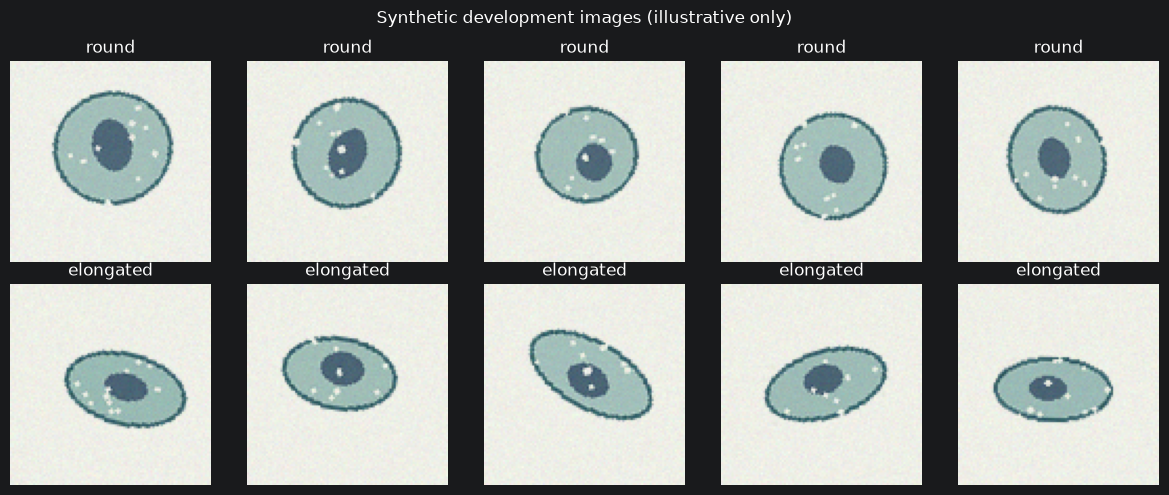

,specimen_id,image_index,label,class_name,cohort,domain
0,DEV_ROUND_000,0,0,round,DEV,development
1,DEV_ROUND_000,1,0,round,DEV,development
2,DEV_ROUND_000,2,0,round,DEV,development
3,DEV_ROUND_000,3,0,round,DEV,development
4,DEV_ROUND_000,4,0,round,DEV,development


In [3]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for label in range(NUM_CLASSES):
    idx = np.flatnonzero(y_dev == label)[:5]
    for ax, image_idx in zip(axes[label], idx):
        ax.imshow(X_dev[image_idx])
        ax.set_title(CLASS_NAMES[label])
        ax.axis("off")
plt.suptitle("Synthetic development images (illustrative only)")
plt.tight_layout()
plt.show()

metadata_dev.head()

class_name cohort  images  specimens
 elongated    DEV     480         80
     round    DEV     480         80


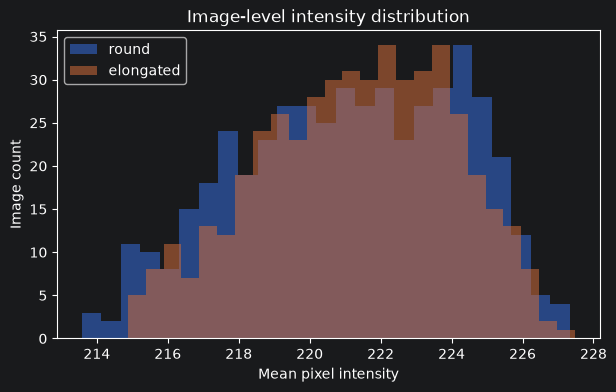

In [4]:
summary = metadata_dev.groupby(["class_name", "cohort"]).agg(
    images=("image_index", "count"),
    specimens=("specimen_id", "nunique")
).reset_index()
print(summary.to_string(index=False))

image_means = X_dev.mean(axis=(1, 2, 3))
plt.figure(figsize=(7, 4))
for label, name in enumerate(CLASS_NAMES):
    plt.hist(image_means[y_dev == label], bins=25, alpha=0.55, label=name)
plt.xlabel("Mean pixel intensity")
plt.ylabel("Image count")
plt.title("Image-level intensity distribution")
plt.legend()
plt.show()

## 7. Patient/specimen-level splitting

We have 80 specimens per class in the development cohort. Within each class, 56 specimens are assigned to training, 12 to validation, and 12 to internal testing. The validation specimens are split again into two disjoint groups:

- `validation_selection`: model selection and early stopping;
- `calibration`: temperature-scaling fit and calibration assessment.

This yields four disjoint specimen sets. The external cohort is generated separately and never enters training, model selection, or calibration.

In [5]:
rng = np.random.default_rng(SEED)
train_specimens, val_specimens, test_specimens = [], [], []
for label in range(NUM_CLASSES):
    class_specimens = metadata_dev.loc[
        metadata_dev["label"] == label, "specimen_id"
    ].drop_duplicates().to_numpy()
    class_specimens = rng.permutation(class_specimens)
    train_specimens.extend(class_specimens[:56])
    val_specimens.extend(class_specimens[56:68])
    test_specimens.extend(class_specimens[68:80])

val_selection_specimens, calibration_specimens = [], []
for label in range(NUM_CLASSES):
    label_validation = [sid for sid in val_specimens if f"_{CLASS_NAMES[label].upper()}_" in sid]
    label_validation = rng.permutation(np.asarray(label_validation))
    val_selection_specimens.extend(label_validation[:6])
    calibration_specimens.extend(label_validation[6:])


def mask_for_specimens(specimen_ids, selected_ids):
    return np.isin(specimen_ids, np.asarray(selected_ids))

m_train = mask_for_specimens(specimen_dev, train_specimens)
m_val = mask_for_specimens(specimen_dev, val_selection_specimens)
m_cal = mask_for_specimens(specimen_dev, calibration_specimens)
m_test = mask_for_specimens(specimen_dev, test_specimens)

X_train, y_train = X_dev[m_train], y_dev[m_train]
X_val, y_val = X_dev[m_val], y_dev[m_val]
X_cal, y_cal = X_dev[m_cal], y_dev[m_cal]
X_test, y_test = X_dev[m_test], y_dev[m_test]

print("Images by split:", {"train": len(y_train), "validation_selection": len(y_val),
                            "calibration": len(y_cal), "test": len(y_test)})

Images by split: {'train': 672, 'validation_selection': 72, 'calibration': 72, 'test': 144}


In [6]:
train_ids = set(train_specimens)
val_ids = set(val_selection_specimens)
cal_ids = set(calibration_specimens)
test_ids = set(test_specimens)
assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(cal_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(cal_ids)
assert val_ids.isdisjoint(test_ids)
assert cal_ids.isdisjoint(test_ids)
assert set(specimen_external).isdisjoint(train_ids | val_ids | cal_ids | test_ids)

split_table = pd.DataFrame({
    "split": ["train", "validation_selection", "calibration", "internal_test", "external"],
    "images": [len(y_train), len(y_val), len(y_cal), len(y_test), len(y_external)],
    "specimens": [len(train_ids), len(val_ids), len(cal_ids), len(test_ids),
                  metadata_external["specimen_id"].nunique()],
    "round_images": [int((y_train==0).sum()), int((y_val==0).sum()),
                     int((y_cal==0).sum()), int((y_test==0).sum()), int((y_external==0).sum())],
    "elongated_images": [int((y_train==1).sum()), int((y_val==1).sum()),
                         int((y_cal==1).sum()), int((y_test==1).sum()), int((y_external==1).sum())]
})
print(split_table.to_string(index=False))
print("\nNo specimen overlap detected across development splits.")

               split  images  specimens  round_images  elongated_images
               train     672        112           336               336
validation_selection      72         12            36                36
         calibration      72         12            36                36
       internal_test     144         24            72                72
            external     240         40           120               120

No specimen overlap detected across development splits.


## 8. Prepare TensorFlow input pipelines

The arrays are stored as unsigned 8-bit images to reduce memory use. The dataset pipeline casts images to `float32`, optionally shuffles only the training examples, batches them, and prefetches batches for more efficient input delivery.

In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("Keras:", getattr(keras, "__version__", "bundled with TensorFlow"))
print("Visible GPU devices:", tf.config.list_physical_devices("GPU"))

BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(buffer_size=len(labels), seed=SEED,
                        reshuffle_each_iteration=True)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val)
cal_ds = make_dataset(X_cal, y_cal)
test_ds = make_dataset(X_test, y_test)
external_ds = make_dataset(X_external, y_external)

TensorFlow: 2.21.0
Keras: 3.15.1
Visible GPU devices: []


## 9. Build a CNN baseline

The CNN is a compact baseline that can be trained without downloading pretrained weights. The final convolutional layer is explicitly named `last_conv` because it will be used later for Grad-CAM.

In [8]:
def build_cnn(input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)):
    inputs = keras.Input(shape=input_shape, name="image")
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.08)(x)
    x = layers.RandomZoom(0.08)(x)
    x = layers.Rescaling(1.0 / 255.0)(x)

    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.Conv2D(128, 3, padding="same", activation="relu",
                      name="last_conv")(x)
    x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.30)(x)
    outputs = layers.Dense(1, activation="sigmoid", name="probability")(x)
    return keras.Model(inputs, outputs, name="synthetic_cell_cnn")

cnn_model = build_cnn()
cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
             keras.metrics.AUC(name="roc_auc")]
)
cnn_model.summary()

Model: "synthetic_cell_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 96, 96, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 24, 24, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 12, 12, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability (Dense)             │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,377 (364.75 KB)

 Trainable params: 93,377 (364.75 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
cnn_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_roc_auc", mode="max", patience=5,
        restore_best_weights=True, verbose=1
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5, patience=2,
        min_lr=1e-6, verbose=1
    )
]

cnn_history = cnn_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
    callbacks=cnn_callbacks,
    verbose=1
)

Epoch 1/20


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


21/21 ━━━━━━━━━━━━━━━━━━━━ 13s 358ms/step - accuracy: 0.4821 - loss: 0.7096 - roc_auc: 0.4812 - val_accuracy: 0.5000 - val_loss: 0.6954 - val_roc_auc: 0.5000 - learning_rate: 0.0010
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 318ms/step - accuracy: 0.5119 - loss: 0.6941 - roc_auc: 0.5080 - val_accuracy: 0.5000 - val_loss: 0.6933 - val_roc_auc: 0.5000 - learning_rate: 0.0010
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 186ms/step - accuracy: 0.5000 - loss: 0.6936 - roc_auc: 0.4876 - val_accuracy: 0.5000 - val_loss: 0.6931 - val_roc_auc: 0.5000 - learning_rate: 0.0010
Epoch 4/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 151ms/step - accuracy: 0.4836 - loss: 0.6933 - roc_auc: 0.5073 - val_accuracy: 0.5000 - val_loss: 0.6932 - val_roc_auc: 0.5000 - learning_rate: 0.0010
Epoch 5/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step - accuracy: 0.5030 - loss: 0.6932 - roc_auc: 0.5021
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 151ms/step - accuracy: 0.5030 - 

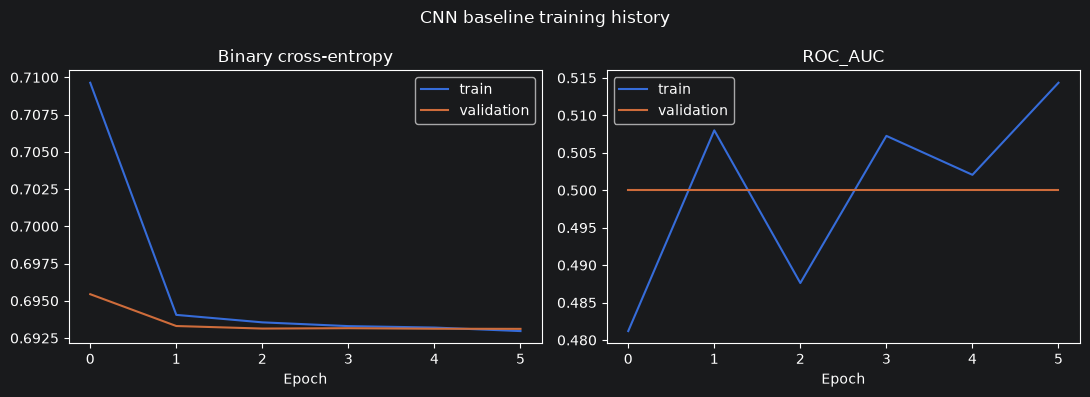

In [10]:
def plot_history(history, title):
    hist = pd.DataFrame(history.history)
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(hist["loss"], label="train")
    axes[0].plot(hist["val_loss"], label="validation")
    axes[0].set_title("Binary cross-entropy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    metric_name = "roc_auc" if "roc_auc" in hist else "accuracy"
    val_metric_name = "val_" + metric_name
    axes[1].plot(hist[metric_name], label="train")
    axes[1].plot(hist[val_metric_name], label="validation")
    axes[1].set_title(metric_name.upper())
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(cnn_history, "CNN baseline training history")

## 10. Build a MobileNetV2 transfer-learning model

The main transfer-learning experiment uses MobileNetV2 with `include_top=False`. ImageNet weights are requested by default. The first run may need an internet connection to download those weights.

If weights cannot be downloaded, the code falls back to random initialization so that the architecture can still be demonstrated. **A randomly initialized backbone is not transfer learning.** The `PRETRAINED_WEIGHTS_LOADED` flag records which case occurred, and results must be described accordingly.

MobileNetV2 expects its application-specific preprocessing, which scales pixels to approximately $[-1,1]$. The `Rescaling` layer below implements that transformation.

In [11]:
LOAD_IMAGENET_WEIGHTS = True
PRETRAINED_WEIGHTS_LOADED = False

try:
    requested_weights = "imagenet" if LOAD_IMAGENET_WEIGHTS else None
    base_model = keras.applications.MobileNetV2(
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        include_top=False,
        weights=requested_weights
    )
    PRETRAINED_WEIGHTS_LOADED = requested_weights == "imagenet"
except Exception as exc:
    print("ImageNet weights could not be loaded:", repr(exc))
    print("Falling back to random initialization; this is NOT pretrained transfer learning.")
    base_model = keras.applications.MobileNetV2(
        input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3),
        include_top=False,
        weights=None
    )

# Freeze the backbone only when genuine ImageNet weights were loaded.
# If loading failed, train the randomly initialized MobileNetV2 end-to-end.
base_model.trainable = not PRETRAINED_WEIGHTS_LOADED

inputs = keras.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name="image")
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.06)(x)
x = layers.RandomZoom(0.06)(x)
x = layers.Rescaling(scale=1.0 / 127.5, offset=-1.0)(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(1, activation="sigmoid", name="probability")(x)
transfer_model = keras.Model(inputs, outputs, name="mobilenetv2_cell_classifier")

transfer_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3 if PRETRAINED_WEIGHTS_LOADED else 1e-4
    ),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
             keras.metrics.AUC(name="roc_auc")]
)
print("ImageNet pretrained weights loaded:", PRETRAINED_WEIGHTS_LOADED)
print("Backbone trainable at initialization:", base_model.trainable)
transfer_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 74s 8us/step
ImageNet pretrained weights loaded: True
Backbone trainable at initialization: False


Model: "mobilenetv2_cell_classifier"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip_1 (RandomFlip)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 96, 96, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ probability (Dense)             │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [12]:
transfer_head_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_roc_auc", mode="max", patience=3,
            restore_best_weights=True, verbose=1
        )
    ],
    verbose=1
)

Epoch 1/8


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


21/21 ━━━━━━━━━━━━━━━━━━━━ 22s 306ms/step - accuracy: 0.8125 - loss: 0.4285 - roc_auc: 0.9037 - val_accuracy: 0.9583 - val_loss: 0.2606 - val_roc_auc: 1.0000
Epoch 2/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 141ms/step - accuracy: 0.9673 - loss: 0.1834 - roc_auc: 0.9954 - val_accuracy: 0.9722 - val_loss: 0.1605 - val_roc_auc: 1.0000
Epoch 3/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 145ms/step - accuracy: 0.9777 - loss: 0.1147 - roc_auc: 0.9990 - val_accuracy: 0.9861 - val_loss: 0.1217 - val_roc_auc: 1.0000
Epoch 4/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 3s 143ms/step - accuracy: 0.9911 - loss: 0.0879 - roc_auc: 0.9993 - val_accuracy: 0.9861 - val_loss: 0.1104 - val_roc_auc: 1.0000
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


### Fine-tune the last layers (or continue end-to-end training)

When ImageNet weights are available, fine-tuning uses a lower learning rate, unfreezes only the last part of the backbone, and keeps Batch Normalization layers frozen to reduce instability on a small dataset. After changing `trainable`, the model is recompiled.

If ImageNet weights were unavailable, the backbone was trainable from the start and is trained from scratch. The second stage then continues end-to-end training at a lower learning rate; it must not be described as pretrained fine-tuning.

In [13]:
if PRETRAINED_WEIGHTS_LOADED:
    base_model.trainable = True
    for layer in base_model.layers[:-30]:
        layer.trainable = False
    for layer in base_model.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
else:
    base_model.trainable = True  # continue training the randomly initialized model

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[keras.metrics.BinaryAccuracy(name="accuracy"),
             keras.metrics.AUC(name="roc_auc")]
)

transfer_finetune_history = transfer_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=8,
    callbacks=[
        keras.callbacks.EarlyStopping(
            monitor="val_roc_auc", mode="max", patience=3,
            restore_best_weights=True, verbose=1
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2,
            min_lr=1e-7, verbose=1
        )
    ],
    verbose=1
)

Epoch 1/8


G:\CancerAI\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


21/21 ━━━━━━━━━━━━━━━━━━━━ 12s 248ms/step - accuracy: 0.9702 - loss: 0.1272 - roc_auc: 0.9966 - val_accuracy: 0.9444 - val_loss: 0.1865 - val_roc_auc: 1.0000 - learning_rate: 1.0000e-05
Epoch 2/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 173ms/step - accuracy: 0.9940 - loss: 0.0300 - roc_auc: 0.9999 - val_accuracy: 0.9444 - val_loss: 0.1827 - val_roc_auc: 1.0000 - learning_rate: 1.0000e-05
Epoch 3/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 172ms/step - accuracy: 0.9955 - loss: 0.0160 - roc_auc: 0.9999 - val_accuracy: 0.9583 - val_loss: 0.1015 - val_roc_auc: 1.0000 - learning_rate: 1.0000e-05
Epoch 4/8
21/21 ━━━━━━━━━━━━━━━━━━━━ 4s 169ms/step - accuracy: 0.9985 - loss: 0.0104 - roc_auc: 1.0000 - val_accuracy: 0.9583 - val_loss: 0.0958 - val_roc_auc: 1.0000 - learning_rate: 1.0000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


## 11. Compare candidate models using validation data only

The internal test set and external cohort remain untouched. Candidate selection uses ROC-AUC on `validation_selection`. If ImageNet weights did not load, label the MobileNetV2 candidate as a randomly initialized architecture rather than a pretrained model.

In [14]:
def predict_probabilities(model, images, batch_size=32):
    return model.predict(images.astype(np.float32), batch_size=batch_size, verbose=0).reshape(-1)

cnn_val_probs = predict_probabilities(cnn_model, X_val)
transfer_val_probs = predict_probabilities(transfer_model, X_val)

candidate_scores = {
    "CNN baseline": roc_auc_score(y_val, cnn_val_probs),
    "MobileNetV2" + (" pretrained" if PRETRAINED_WEIGHTS_LOADED else " random-init"): 
        roc_auc_score(y_val, transfer_val_probs)
}
print(pd.Series(candidate_scores, name="validation_roc_auc").sort_values(ascending=False))

selected_name = max(candidate_scores, key=candidate_scores.get)
selected_model = cnn_model if selected_name == "CNN baseline" else transfer_model
print("Selected using validation ROC-AUC:", selected_name)

MobileNetV2 pretrained    1.00000
CNN baseline              0.60108
Name: validation_roc_auc, dtype: float64
Selected using validation ROC-AUC: MobileNetV2 pretrained


## 12. Probability calibration on a separate calibration split

Calibration is fitted only on the reserved `calibration` specimens. We use temperature scaling on model logits and choose the temperature by minimizing calibration-set log loss. The internal test set and external cohort are not used to fit the temperature.

This is a demonstration. A small calibration set can produce an unstable temperature estimate; in real work, assess uncertainty and use a sufficiently large, representative calibration cohort.

In [15]:
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit

cal_raw_probs = predict_probabilities(selected_model, X_cal)
cal_logits = logit(np.clip(cal_raw_probs, 1e-6, 1 - 1e-6))

def temperature_nll(temperature, logits, labels):
    probs = expit(logits / temperature)
    return log_loss(labels, probs, labels=[0, 1])

opt = minimize_scalar(
    temperature_nll,
    bounds=(0.25, 4.0),
    method="bounded",
    args=(cal_logits, y_cal)
)
TEMPERATURE = float(opt.x)
print("Fitted temperature:", TEMPERATURE)
print("Calibration log loss before:", temperature_nll(1.0, cal_logits, y_cal))
print("Calibration log loss after:", temperature_nll(TEMPERATURE, cal_logits, y_cal))


def calibrate_probabilities(raw_probs, temperature=TEMPERATURE):
    raw_logits = logit(np.clip(np.asarray(raw_probs), 1e-6, 1 - 1e-6))
    return expit(raw_logits / temperature)

Fitted temperature: 0.3910338351436306
Calibration log loss before: 0.1420617699623108
Calibration log loss after: 0.0937788188457489


## 13. Evaluation utilities

We report sensitivity and specificity in addition to precision, recall, F1-score, ROC-AUC, average precision, Brier score, and log loss. For this binary task, label `1` is `elongated` and label `0` is `round`.

In [16]:
def expected_calibration_error(y_true, probabilities, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probabilities).astype(float)
    bin_edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for left, right in zip(bin_edges[:-1], bin_edges[1:]):
        in_bin = (probabilities >= left) & (probabilities < right)
        if in_bin.any():
            confidence = probabilities[in_bin].mean()
            observed_frequency = y_true[in_bin].mean()
            ece += in_bin.mean() * abs(confidence - observed_frequency)
    return float(ece)


def evaluate_binary_classifier(y_true, probabilities, threshold=0.5, label="dataset"):
    probabilities = np.asarray(probabilities).reshape(-1)
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()
    specificity = tn / (tn + fp) if (tn + fp) else np.nan
    return {
        "dataset": label,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, predictions),
        "balanced_accuracy": balanced_accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "sensitivity_recall": recall_score(y_true, predictions, zero_division=0),
        "specificity": specificity,
        "f1": f1_score(y_true, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_true, probabilities),
        "average_precision": average_precision_score(y_true, probabilities),
        "brier_score": brier_score_loss(y_true, probabilities),
        "log_loss": log_loss(y_true, probabilities, labels=[0, 1]),
        "ece": expected_calibration_error(y_true, probabilities),
    }

## 14. Final internal test evaluation

After candidate selection and calibration are complete, evaluate once on the internal test set. Do not use this result to go back and change the model. If changes are made after seeing test performance, a new untouched test cohort is needed for an unbiased final estimate.

In [17]:
test_raw_probs = predict_probabilities(selected_model, X_test)
test_probs = calibrate_probabilities(test_raw_probs)
test_results = evaluate_binary_classifier(y_test, test_probs, threshold=0.5,
                                          label="internal_test")
print(pd.Series(test_results).to_string())

test_predictions = (test_probs >= 0.5).astype(int)
print("\nClassification report:")
print(classification_report(y_test, test_predictions, target_names=CLASS_NAMES,
                            digits=3, zero_division=0))

dataset               internal_test
threshold                       0.5
accuracy                   0.909722
balanced_accuracy          0.909722
precision                  0.847059
sensitivity_recall              1.0
specificity                0.819444
f1                         0.917197
roc_auc                         1.0
average_precision               1.0
brier_score                0.066795
log_loss                   0.212895
ece                        0.101832

Classification report:
              precision    recall  f1-score   support

       round      1.000     0.819     0.901        72
   elongated      0.847     1.000     0.917        72

    accuracy                          0.910       144
   macro avg      0.924     0.910     0.909       144
weighted avg      0.924     0.910     0.909       144



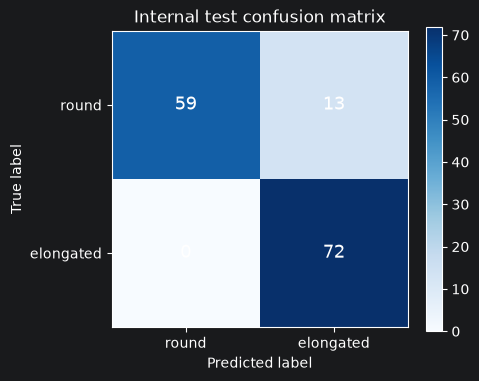

In [18]:
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks([0, 1], labels=CLASS_NAMES)
ax.set_yticks([0, 1], labels=CLASS_NAMES)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Internal test confusion matrix")
for (i, j), value in np.ndenumerate(cm):
    ax.text(j, i, str(value), ha="center", va="center", fontsize=13)
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

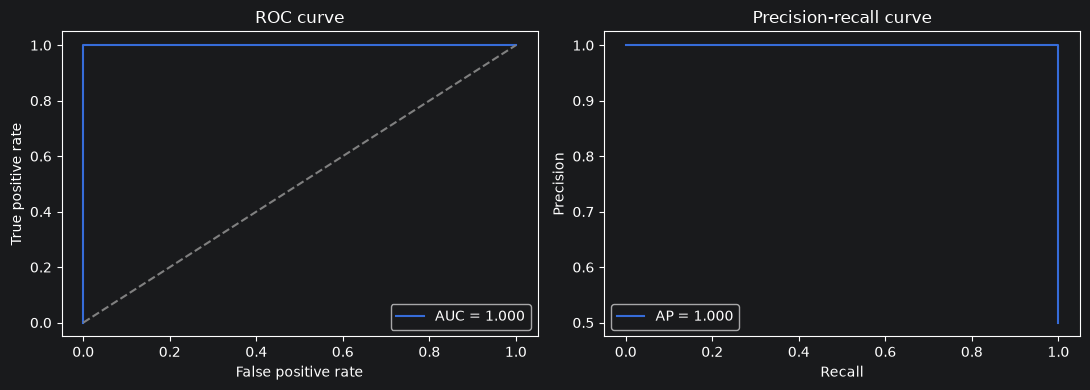

In [19]:
fpr, tpr, _ = roc_curve(y_test, test_probs)
precision, recall, _ = precision_recall_curve(y_test, test_probs)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(fpr, tpr, label=f"AUC = {test_results['roc_auc']:.3f}")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curve")
axes[0].legend()
axes[1].plot(recall, precision, label=f"AP = {test_results['average_precision']:.3f}")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Precision-recall curve")
axes[1].legend()
plt.tight_layout()
plt.show()

## 15. Probability calibration assessment

A calibration curve compares average predicted probability with observed event frequency in probability bins. A well-calibrated model should approximately follow the diagonal. Calibration is distinct from discrimination: a model can rank examples well while producing overconfident probabilities.

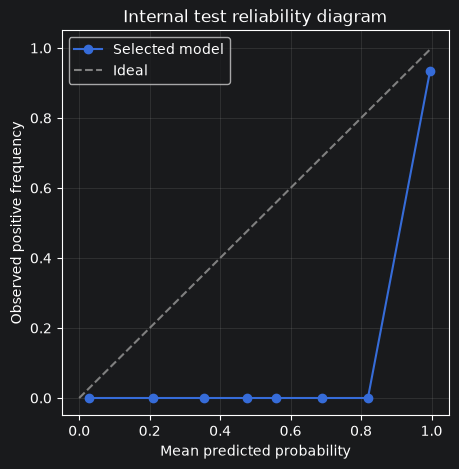

Brier score: 0.06679484993219376
ECE: 0.10183159697685873


In [20]:
prob_true, prob_pred = calibration_curve(y_test, test_probs, n_bins=8, strategy="uniform")
plt.figure(figsize=(5, 5))
plt.plot(prob_pred, prob_true, marker="o", label="Selected model")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Ideal")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed positive frequency")
plt.title("Internal test reliability diagram")
plt.legend()
plt.grid(alpha=0.2)
plt.show()
print("Brier score:", brier_score_loss(y_test, test_probs))
print("ECE:", expected_calibration_error(y_test, test_probs))

## 16. External validation under simulated domain shift

The external cohort was generated independently with a different acquisition appearance. It has not been used for model selection or calibration. Apply the same frozen preprocessing and fitted temperature, then compare its performance with internal test performance.

In a real biomedical study, an external cohort should ideally come from a genuinely independent institution, scanner, acquisition period, or study population, with harmonized label definitions and patient-level deduplication.

In [21]:
external_raw_probs = predict_probabilities(selected_model, X_external)
external_probs = calibrate_probabilities(external_raw_probs)
external_results = evaluate_binary_classifier(
    y_external, external_probs, threshold=0.5, label="external_synthetic_cohort"
)
comparison = pd.DataFrame([test_results, external_results]).set_index("dataset")
print(comparison.T.to_string())

dataset             internal_test  external_synthetic_cohort
threshold                0.500000                   0.500000
accuracy                 0.909722                   0.991667
balanced_accuracy        0.909722                   0.991667
precision                0.847059                   1.000000
sensitivity_recall       1.000000                   0.983333
specificity              0.819444                   1.000000
f1                       0.917197                   0.991597
roc_auc                  1.000000                   1.000000
average_precision        1.000000                   1.000000
brier_score              0.066795                   0.004744
log_loss                 0.212895                   0.022071
ece                      0.101832                   0.018551


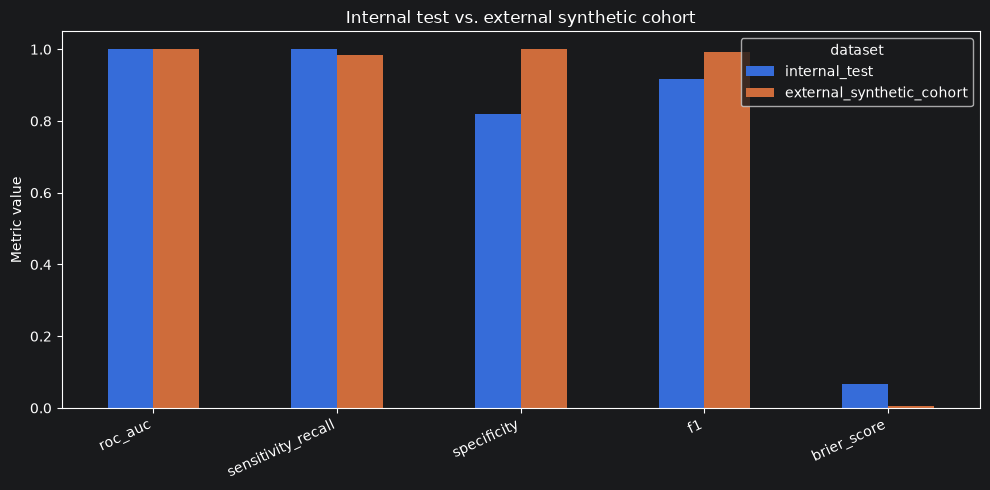

In [22]:
metrics_to_plot = ["roc_auc", "sensitivity_recall", "specificity", "f1", "brier_score"]
comparison[metrics_to_plot].T.plot(kind="bar", figsize=(10, 5))
plt.title("Internal test vs. external synthetic cohort")
plt.ylabel("Metric value")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 17. Error analysis

Inspect false positives and false negatives rather than looking only at aggregate metrics. In a real study, errors should be reviewed by qualified domain experts and stratified by relevant subgroups, acquisition site, image quality, and specimen characteristics where permitted.

In [23]:
error_table = pd.DataFrame({
    "true_label": y_test,
    "predicted_label": test_predictions,
    "probability_elongated": test_probs,
    "specimen_id": specimen_dev[m_test],
})
error_table["true_name"] = error_table["true_label"].map(dict(enumerate(CLASS_NAMES)))
error_table["predicted_name"] = error_table["predicted_label"].map(dict(enumerate(CLASS_NAMES)))
error_table["error_type"] = np.where(
    error_table["true_label"] == error_table["predicted_label"], "correct",
    np.where(error_table["true_label"] == 1, "false_negative", "false_positive")
)
print(error_table["error_type"].value_counts())
error_table.loc[error_table["error_type"] != "correct"].head(12)

error_type
correct           131
false_positive     13
Name: count, dtype: int64


,true_label,predicted_label,probability_elongated,specimen_id,true_name,predicted_name,error_type
3,0,1,0.889234,DEV_ROUND_008,round,elongated,false_positive
9,0,1,0.916896,DEV_ROUND_012,round,elongated,false_positive
17,0,1,0.686805,DEV_ROUND_013,round,elongated,false_positive
19,0,1,0.810593,DEV_ROUND_014,round,elongated,false_positive
25,0,1,0.625583,DEV_ROUND_035,round,elongated,false_positive
34,0,1,0.926108,DEV_ROUND_036,round,elongated,false_positive
42,0,1,0.982717,DEV_ROUND_053,round,elongated,false_positive
43,0,1,0.743064,DEV_ROUND_053,round,elongated,false_positive
48,0,1,0.713682,DEV_ROUND_064,round,elongated,false_positive
57,0,1,0.828529,DEV_ROUND_065,round,elongated,false_positive


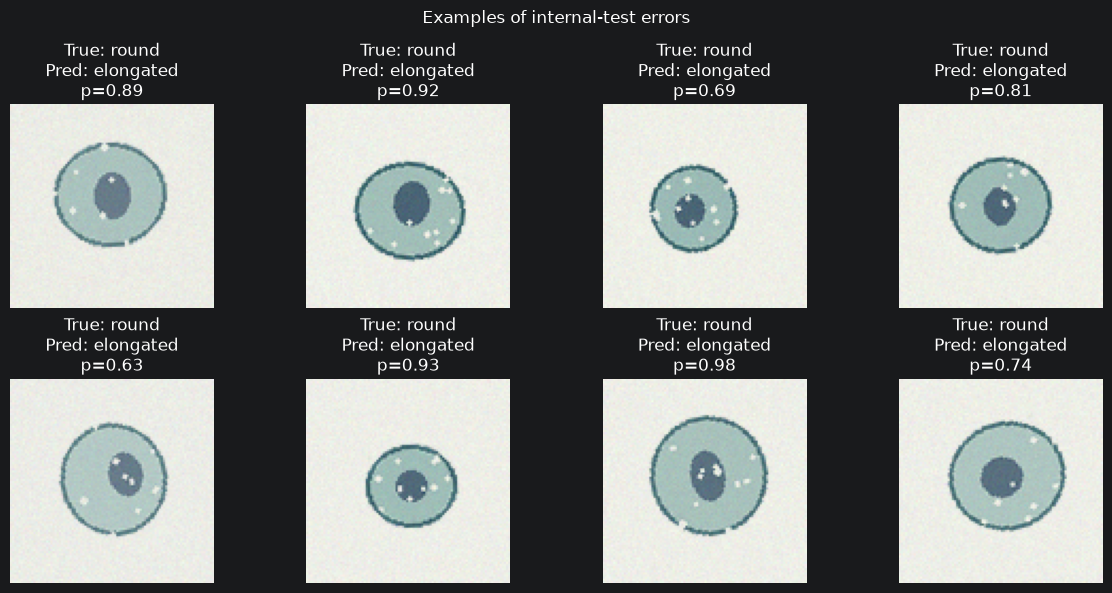

In [24]:
error_indices_local = np.flatnonzero(test_predictions != y_test)
if len(error_indices_local):
    n_show = min(8, len(error_indices_local))
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for ax, idx in zip(axes.flat, error_indices_local[:n_show]):
        ax.imshow(X_test[idx])
        ax.set_title(f"True: {CLASS_NAMES[y_test[idx]]}\nPred: {CLASS_NAMES[test_predictions[idx]]}\np={test_probs[idx]:.2f}")
        ax.axis("off")
    for ax in axes.flat[n_show:]:
        ax.axis("off")
    plt.suptitle("Examples of internal-test errors")
    plt.tight_layout()
    plt.show()
else:
    print("No misclassified examples in this synthetic test split.")

## 18. Explainability with Grad-CAM

Grad-CAM highlights image regions that influence a selected model score through gradients flowing into a convolutional layer. We use the CNN baseline because its final convolutional layer has a stable, explicit name (`last_conv`). The heatmap is a debugging aid: it does not prove that the model uses biologically meaningful evidence.

In [25]:
def make_gradcam_heatmap(image, model, last_conv_layer_name="last_conv", class_index=1):
    grad_model = keras.Model(
        inputs=model.inputs,
        outputs=[model.get_layer(last_conv_layer_name).output, model.output]
    )
    image_batch = np.expand_dims(image.astype(np.float32), axis=0)
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image_batch, training=False)
        if class_index == 1:
            class_score = predictions[:, 0]
        else:
            class_score = 1.0 - predictions[:, 0]
    grads = tape.gradient(class_score, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
    heatmap = tf.nn.relu(heatmap)
    heatmap = heatmap / (tf.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def display_gradcam(image, heatmap, alpha=0.38):
    heatmap_img = Image.fromarray(np.uint8(255 * heatmap)).resize(
        (image.shape[1], image.shape[0]), resample=Image.Resampling.BICUBIC
    )
    heat = np.asarray(heatmap_img).astype(np.float32) / 255.0
    color = plt.get_cmap("jet")(heat)[..., :3]
    overlay = np.clip((1 - alpha) * image / 255.0 + alpha * color, 0, 1)
    return overlay

G:\CancerAI\.venv\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['image']
Received: inputs=Tensor(shape=(1, 96, 96, 3))
  warnings.warn(msg)


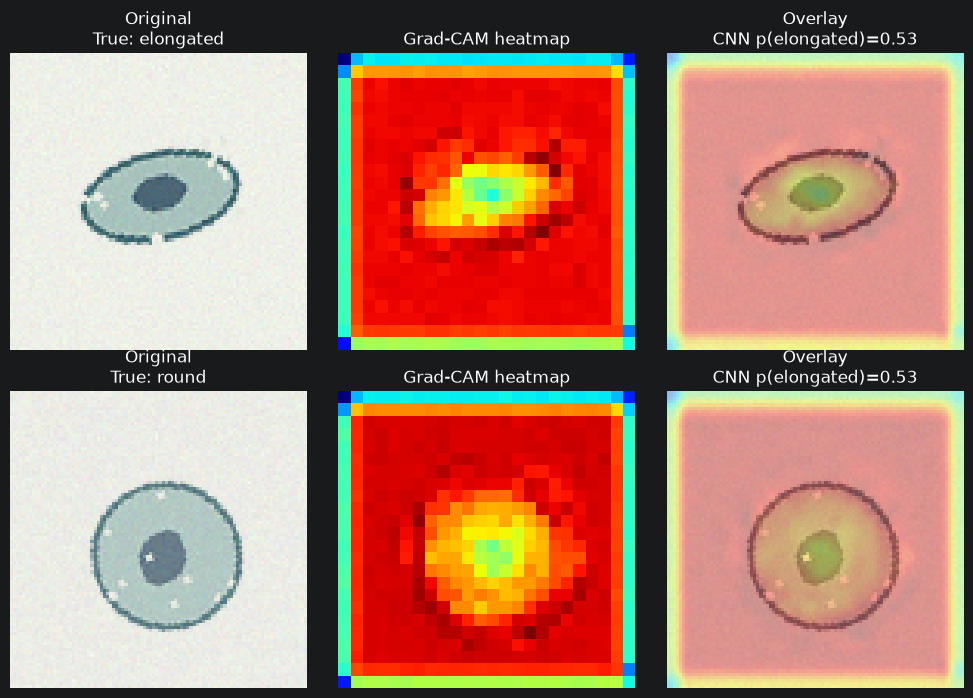

In [26]:
# Select examples based on the CNN baseline, which is the model explained below.
cnn_test_probs = predict_probabilities(cnn_model, X_test)
cnn_test_predictions = (cnn_test_probs >= 0.5).astype(int)
cnn_error_indices = np.flatnonzero(cnn_test_predictions != y_test)
cnn_correct_indices = np.flatnonzero(cnn_test_predictions == y_test)
explain_indices = []
if len(cnn_correct_indices):
    explain_indices.append(int(cnn_correct_indices[0]))
if len(cnn_error_indices):
    explain_indices.append(int(cnn_error_indices[0]))
if not explain_indices:
    explain_indices = [0]

fig, axes = plt.subplots(len(explain_indices), 3,
                         figsize=(10, 3.5 * len(explain_indices)))
if len(explain_indices) == 1:
    axes = np.expand_dims(axes, axis=0)
for row, idx in enumerate(explain_indices):
    image = X_test[idx]
    raw_probability = float(predict_probabilities(cnn_model, image[None, ...])[0])
    predicted_class = int(raw_probability >= 0.5)
    heatmap = make_gradcam_heatmap(image, cnn_model, class_index=predicted_class)
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"Original\nTrue: {CLASS_NAMES[y_test[idx]]}")
    axes[row, 1].imshow(heatmap, cmap="jet")
    axes[row, 1].set_title("Grad-CAM heatmap")
    axes[row, 2].imshow(display_gradcam(image, heatmap))
    axes[row, 2].set_title(f"Overlay\nCNN p(elongated)={raw_probability:.2f}")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

### Grad-CAM interpretation checklist

- Does the heatmap focus on the cell region rather than the background or image border?
- Does attention move when the cell is translated or when acquisition appearance changes?
- Are predictions stable under plausible, label-preserving transformations?
- Do false positives and false negatives show different attention patterns?
- Can a domain expert assess whether highlighted regions are biologically plausible?

A visually attractive heatmap is not proof of model validity. Consider perturbation tests, occlusion sensitivity, and independent expert review in real studies.

## 19. Reproducibility and artifact saving

Save the selected model in the native `.keras` format, together with metadata that specifies class order, input size, model selection metric, temperature, and whether ImageNet weights were actually loaded. Save the CNN separately because it is the model used for the Grad-CAM demonstration.

In [27]:
selected_model_path = PROJECT_DIR / "selected_capstone_model.keras"
cnn_model_path = PROJECT_DIR / "cnn_gradcam_model.keras"
metadata_path = PROJECT_DIR / "model_metadata.json"
predictions_path = PROJECT_DIR / "internal_test_predictions.csv"

selected_model.save(selected_model_path)
cnn_model.save(cnn_model_path)

model_metadata = {
    "project": "synthetic_cell_morphology_classification",
    "class_names": CLASS_NAMES,
    "positive_class": "elongated",
    "input_shape": [IMAGE_SIZE, IMAGE_SIZE, 3],
    "selected_model": selected_name,
    "selection_metric": "validation_selection_roc_auc",
    "temperature_scaling_temperature": TEMPERATURE,
    "pretrained_imagenet_weights_loaded": bool(PRETRAINED_WEIGHTS_LOADED),
    "random_seed": SEED,
    "synthetic_data_only": True,
    "not_for_diagnostic_use": True,
}
with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=2)

pd.DataFrame({
    "true_label": y_test,
    "probability_elongated_calibrated": test_probs,
    "predicted_label": test_predictions,
    "specimen_id": specimen_dev[m_test],
}).to_csv(predictions_path, index=False)

print("Saved artifacts:")
for path in [selected_model_path, cnn_model_path, metadata_path, predictions_path]:
    print(path, "exists:", path.exists())

Saved artifacts:
capstone_outputs\selected_capstone_model.keras exists: True
capstone_outputs\cnn_gradcam_model.keras exists: True
capstone_outputs\model_metadata.json exists: True
capstone_outputs\internal_test_predictions.csv exists: True


In [28]:
# Reload the selected model and verify that predictions are numerically consistent.
reloaded_model = keras.models.load_model(selected_model_path)
reloaded_probs = predict_probabilities(reloaded_model, X_test[:16])
original_probs = predict_probabilities(selected_model, X_test[:16])
max_abs_difference = float(np.max(np.abs(reloaded_probs - original_probs)))
print("Maximum prediction difference after reload:", max_abs_difference)
assert max_abs_difference < 1e-5

Maximum prediction difference after reload: 0.0


## 20. Model card

Complete this model card when reporting the project. Replace placeholders with results from the executed notebook. Do not present synthetic-data metrics as evidence for real-world biomedical performance.

| Field | Description |
|---|---|
| Model name | Synthetic Cell Morphology Classifier |
| Version | 1.0 (educational capstone) |
| Intended use | Demonstrate an end-to-end image-classification workflow on synthetic images |
| Out-of-scope use | Diagnosis, screening, triage, treatment decisions, or research claims about real cells |
| Input | RGB image, 96 × 96 pixels |
| Output | Probability of the simulated `elongated` morphology label |
| Development data | Synthetic microscopy-like images, grouped by simulated specimen |
| External data | Independently generated synthetic cohort with acquisition-style shift |
| Split strategy | Specimen-level development, validation, calibration, and internal test splits |
| Selection criterion | Validation ROC-AUC |
| Calibration | Temperature scaling fitted on a dedicated calibration split |
| Explainability | Grad-CAM demonstration on the CNN baseline |
| Known limitations | Synthetic data, small sample size, artificial labels, simulated domain shift, no clinical validation |
| Ethical considerations | Not a diagnostic device; not validated for people, specimens, or clinical workflows |

### Results to report

- Selected architecture: `________________________`
- Validation ROC-AUC: `________________________`
- Internal test ROC-AUC: `________________________`
- Internal test sensitivity / specificity: `________________________`
- Internal test Brier score / ECE: `________________________`
- External synthetic cohort ROC-AUC: `________________________`
- ImageNet weights loaded: `Yes / No`
- Important failure modes: `________________________`

## 21. Responsible AI and limitations

This project is deliberately synthetic and should be interpreted as a reproducible programming exercise. A real biomedical imaging study would require, at minimum:

1. A clearly defined clinical or biological target and a defensible reference standard.
2. Appropriate approvals, data governance, privacy protection, and access controls.
3. Patient/specimen-level deduplication and split design agreed before model development.
4. Representative data across sites, devices, operators, demographic groups, and acquisition protocols.
5. Independent external validation with confidence intervals and subgroup analysis.
6. Calibration analysis at the intended deployment prevalence and decision context.
7. Expert review of model errors and explainability outputs.
8. Prospective evaluation and monitoring before any consequential use.

Grad-CAM can highlight regions associated with a score, but it does not establish causality, biological relevance, or fairness. A model may exploit shortcuts such as background texture, borders, staining artifacts, or acquisition signatures.

## 22. Exercises

1. Change the number of images per specimen and explain why group-level splitting remains necessary.
2. Introduce more severe external blur and color shift. Quantify the change in ROC-AUC, sensitivity, and calibration.
3. Replace the CNN with a ResNet or EfficientNet backbone. Keep model selection restricted to validation data.
4. Compare temperature scaling with no calibration. Report log loss, Brier score, and ECE on the untouched test set.
5. Implement a patient-level bootstrap confidence interval for sensitivity and specificity.
6. Create an occlusion-sensitivity map and compare it with Grad-CAM.
7. Write a one-page model card using the actual results from your run.
8. Describe the additional evidence needed before this workflow could be studied on real biomedical images.

## Key takeaways

- Split at the patient/specimen level before image-level modeling.
- Keep model selection, calibration, internal test, and external validation conceptually separate.
- Transfer learning requires genuinely pretrained weights; random initialization is not transfer learning.
- Discrimination, calibration, and external generalization are different properties.
- Grad-CAM is a diagnostic visualization, not a causal explanation.
- Reproducible artifacts and a model card are part of a complete deep-learning project.

## References and official documentation

1. TensorFlow. **Image classification tutorial.** https://www.tensorflow.org/tutorials/images/classification
2. TensorFlow. **Load and preprocess images.** https://www.tensorflow.org/tutorials/load_data/images
3. Keras. **MobileNetV2 application.** https://keras.io/api/applications/mobilenet/
4. Keras. **Transfer learning and fine-tuning.** https://keras.io/guides/transfer_learning/
5. Keras. **Model saving and serialization.** https://keras.io/guides/serialization_and_saving/
6. scikit-learn. **Probability calibration.** https://scikit-learn.org/stable/modules/calibration.html
7. scikit-learn. **Calibration curve.** https://scikit-learn.org/stable/modules/generated/sklearn.calibration.calibration_curve.html

---

**End of Notebook 12 — Deep Learning with TensorFlow**  
This completes the 12-notebook educational roadmap. The repository should be reviewed by executing every notebook in the target environment before being published as a fully tested course.